# Application of LASSO: Beating Regular Regression on House Prices

**The question.** Given the same inputs, does LASSO predict sale prices better than regular linear regression?

Regular regression minimizes RSS. LASSO minimizes

$$\text{RSS} + \lambda \sum_j |\beta_j|$$

**When should LASSO help?** When there are many inputs compared with the number of rows, and many of those inputs are not useful. Regression has to give every input a coefficient, even one based on only a few houses. LASSO can set it to 0.

**A fair contest.** Both models get exactly the same original inputs, with no squares or interactions.

## Setup

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer, make_column_selector
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Lasso, LassoCV
from sklearn.metrics import mean_squared_error, r2_score

warnings.filterwarnings("ignore", message="Found unknown categories")

plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "axes.titlesize": 13, "axes.titlelocation": "left", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "xtick.color": "#52514e", "ytick.color": "#52514e",
})
BLUE, INK = "#2a78d6", "#52514e"

## The data: Ames, Iowa home sales

Sales from 2006 to 2010 (De Cock, 2011). Each row is one house, described by 79 inputs. Here are a few:

| Input | Type | Example |
|:--|:--|:--|
| `GrLivArea` | Number | Above-ground living area (sq ft) |
| `OverallQual` | Number | Overall quality, rated 1 to 10 |
| `YearBuilt` | Number | Year of construction |
| `Neighborhood` | Text | `CollgCr`, `StoneBr`, ... |
| `RoofMatl` | Text | Roof material |
| **`SalePrice`** | **Number** | **What we predict (dollars)** |

In [2]:
# Once this file is on the course site, students can use this path instead:
# "https://bryantstats.github.io/math460/data/ames_house_prices.csv"
df = pd.read_csv("../../data/ames_house_prices.csv")

X = df.drop(columns="SalePrice")
y = df["SalePrice"]

print(f"{X.shape[0]} houses, {X.shape[1]} inputs "
      f"({X.select_dtypes('number').shape[1]} numeric, {X.select_dtypes(exclude='number').shape[1]} text)")
print(f"Sold {df['YrSold'].min()} to {df['YrSold'].max()}")
df[["Neighborhood", "GrLivArea", "OverallQual", "YearBuilt", "RoofMatl", "SalePrice"]].head()

1460 houses, 79 inputs (36 numeric, 43 text)
Sold 2006 to 2010


,Neighborhood,GrLivArea,OverallQual,YearBuilt,RoofMatl,SalePrice
0,CollgCr,1710,7,2003,CompShg,208500
1,Veenker,1262,6,1976,CompShg,181500
2,CollgCr,1786,7,2001,CompShg,223500
3,Crawfor,1717,7,1915,CompShg,140000
4,NoRidge,2198,8,2000,CompShg,250000


## Preparing the inputs

Models need numbers, so each text input becomes a set of yes/no (1/0) columns, one for each category except a baseline. This is coding, not new information.

- **Numeric inputs:** fill missing values with the median, then standardize.
- **Text inputs:** a blank usually means the house doesn't have the feature, such as no pool, so it becomes the category `None`.
- **Rare categories:** any category with fewer than 10 training houses is merged into one `infrequent` group. This keeps the contest fair to regression, and we will see why later.

In [3]:
def make_prep(min_frequency=10):
    numeric = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
    text = make_pipeline(
        SimpleImputer(strategy="constant", fill_value="None"),
        OneHotEncoder(drop="first", handle_unknown="infrequent_if_exist",
                      min_frequency=min_frequency, sparse_output=False),
    )
    return make_column_transformer(
        (numeric, make_column_selector(dtype_include="number")),
        (text, make_column_selector(dtype_exclude="number")),
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

prep = make_prep()
X_train = prep.fit_transform(X_train_raw)
X_test = prep.transform(X_test_raw)

print("Training houses:", X_train.shape[0], "  Test houses:", X_test.shape[0])
print("Columns after coding:", X_train.shape[1])

Training houses: 1022   Test houses: 438
Columns after coding: 207


## Regular regression vs. LASSO

In [4]:
ols = LinearRegression().fit(X_train, y_train)
lasso = LassoCV(cv=5, random_state=1, max_iter=50000, n_jobs=-1).fit(X_train, y_train)

coef_ols = pd.Series(ols.coef_, index=X_train.columns)
coef_lasso = pd.Series(lasso.coef_, index=X_train.columns)

def summarize(name, model):
    pred = model.predict(X_test)
    return {"Model": name,
            "Train R2": r2_score(y_train, model.predict(X_train)),
            "Test R2": r2_score(y_test, pred),
            "Test RMSE ($)": mean_squared_error(y_test, pred) ** 0.5,
            "Median abs. error ($)": (y_test - pred).abs().median(),
            "Columns used": (model.coef_ != 0).sum()}

print(f"alpha chosen by cross-validation: {lasso.alpha_:.0f}")
pd.DataFrame([summarize("Regular regression", ols), summarize("LASSO", lasso)]).set_index("Model").round(3)

alpha chosen by cross-validation: 242


,Train R2,Test R2,Test RMSE ($),Median abs. error ($),Columns used
Model,,,,,
Regular regression,0.904,0.841,33718.756,15387.314,207
LASSO,0.868,0.870,30490.772,13303.149,82


LASSO wins on all three test measures, including the typical (median) error, and it uses far fewer columns. Regression shows overfitting: it scores much higher on the training houses than on the test houses, while LASSO scores about the same on both.

## Predicted vs. actual prices

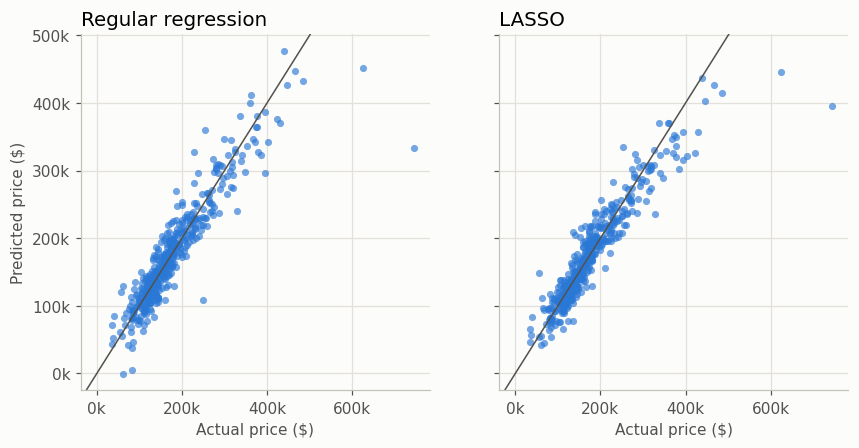

In [5]:
pred_ols = pd.Series(ols.predict(X_test), index=X_test.index)
pred_lasso = pd.Series(lasso.predict(X_test), index=X_test.index)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), sharex=True, sharey=True)
for ax, pred, title in zip(axes, [pred_ols, pred_lasso], ["Regular regression", "LASSO"]):
    ax.axline((0, 0), slope=1, color=INK, lw=1)
    ax.scatter(y_test, pred, s=22, color=BLUE, alpha=0.65, linewidths=0)
    ax.set(title=title, xlabel="Actual price ($)")
    ax.xaxis.set_major_formatter(lambda v, _: f"{v/1000:,.0f}k")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:,.0f}k")
axes[0].set_ylabel("Predicted price ($)")
plt.show()

Points on the line are perfect predictions. Both models badly underprice the most expensive houses, so LASSO doesn't fix everything. Its points sit a little closer to the line overall.

## Why regression does worse: unstable coefficients

In [6]:
numeric_cols = X.select_dtypes("number").columns
yes_no_cols = X_train.columns.difference(numeric_cols)

largest = coef_ols.sort_values(key=abs, ascending=False).head(6).index
pd.DataFrame({
    "Training houses with this": [int(X_train[c].sum()) if c in yes_no_cols else "(numeric)" for c in largest],
    "Regression coefficient ($)": coef_ols[largest].round(0),
    "LASSO coefficient ($)": coef_lasso[largest].round(0),
})

,Training houses with this,Regression coefficient ($),LASSO coefficient ($)
PoolQC_infrequent_sklearn,4,-949008.0,-0.0
Utilities_infrequent_sklearn,1,-71275.0,-0.0
PoolArea,(numeric),54486.0,-2648.0
Neighborhood_StoneBr,17,49389.0,44519.0
Neighborhood_Edwards,69,-42371.0,-9802.0
Neighborhood_OldTown,76,-40587.0,-425.0


In [7]:
print(f"Sum of |coefficients|, regression: ${coef_ols.abs().sum():>12,.0f}")
print(f"Sum of |coefficients|, LASSO:      ${coef_lasso.abs().sum():>12,.0f}")

Sum of |coefficients|, regression: $   3,115,154
Sum of |coefficients|, LASSO:      $     481,977


- Regression's largest coefficient, about −$949,000, belongs to a group of only **4 training houses**, all with pools.
- It is offset by `PoolArea`, because those houses are 13 to 20 SD above average on that input. The net pool effect ranges from about −$236,000 to +$148,000 across the four houses, so regression is memorizing them.
- LASSO sets the group's coefficient to 0 and shrinks the rest, so its coefficients add up to far less.

## What LASSO kept

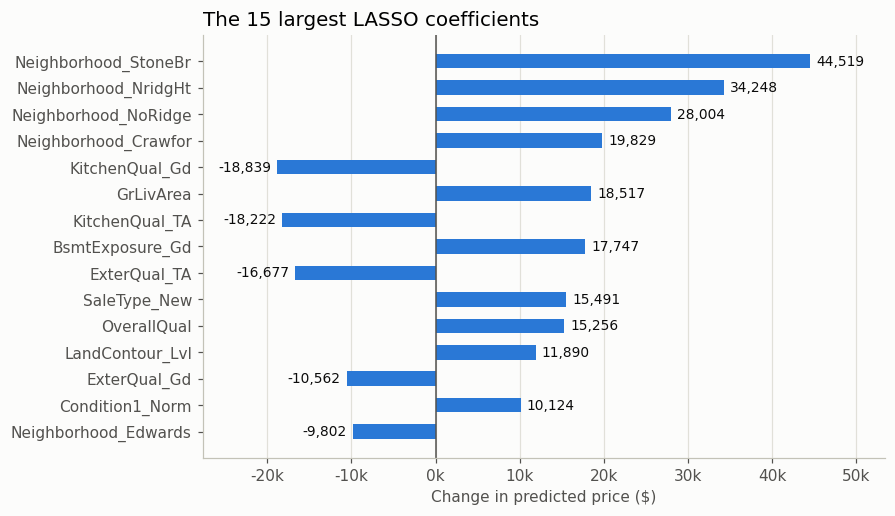

In [8]:
top = coef_lasso[coef_lasso != 0].sort_values(key=abs, ascending=False).head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(top.index, top.values, color=BLUE, height=0.55)
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in top.values], padding=4, color="#0b0b0b", fontsize=9)
ax.axvline(0, color=INK, lw=1)
ax.margins(x=0.14)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(lambda v, _: f"{v/1000:,.0f}k")
ax.set(xlabel="Change in predicted price ($)", title="The 15 largest LASSO coefficients")
plt.show()

- **How to read it:** a numeric input's bar is the effect of 1 SD more. A yes/no column's bar compares that category with its baseline.
- **Sensible results:** more living area (`GrLivArea`), higher quality (`OverallQual`) and certain neighborhoods all raise the predicted price.
- **Negative bars aren't always bad features:** `KitchenQual_Gd` and `KitchenQual_TA` are negative because they compare with the baseline, an excellent kitchen.

## Try it: change `alpha`

Change the value and re-run. Try 10, 100, 242, 1000, 5000 and 20000. What happens to the coefficient count and the test $R^2$ as `alpha` grows?

In [9]:
alpha = 1000

model = Lasso(alpha=alpha, max_iter=50000).fit(X_train, y_train)
print(f"alpha = {alpha}:  {(model.coef_ != 0).sum()} of {X_train.shape[1]} columns kept")
print(f"Train R2 = {r2_score(y_train, model.predict(X_train)):.3f}")
print(f"Test  R2 = {r2_score(y_test, model.predict(X_test)):.3f}")

alpha = 1000:  36 of 207 columns kept
Train R2 = 0.817
Test  R2 = 0.850


## Was that one lucky split?

We repeat the whole contest on 50 random train/test splits. A point **above the line** is a split that LASSO won. This cell takes about 20 seconds to run.

In [10]:
def compare(X, y, n_splits=50, log_price=False, min_frequency=10):
    rows = []
    for seed in range(n_splits):
        a_raw, b_raw, a_y, b_y = train_test_split(X, y, test_size=0.3, random_state=seed)
        p = make_prep(min_frequency)
        a, b = p.fit_transform(a_raw), p.transform(b_raw)
        fit_y = np.log(a_y) if log_price else a_y

        pred_o = LinearRegression().fit(a, fit_y).predict(b)
        cv = LassoCV(cv=5, random_state=1, max_iter=50000, n_jobs=-1).fit(a, fit_y)
        pred_l = cv.predict(b)
        if log_price:
            pred_o, pred_l = np.exp(pred_o), np.exp(pred_l)

        rows.append({"r2_ols": r2_score(b_y, pred_o), "r2_lasso": r2_score(b_y, pred_l),
                     "rmse_ols": mean_squared_error(b_y, pred_o) ** 0.5,
                     "rmse_lasso": mean_squared_error(b_y, pred_l) ** 0.5,
                     "mae_ols": np.median(np.abs(b_y - pred_o)),
                     "mae_lasso": np.median(np.abs(b_y - pred_l)),
                     "kept": (cv.coef_ != 0).sum(), "columns": a.shape[1]})
    return pd.DataFrame(rows)

runs = compare(X, y)
wins = (runs["r2_lasso"] > runs["r2_ols"]).sum()

print(f"LASSO had the higher test R2 on {wins} of {len(runs)} splits ({wins / len(runs):.0%})")
print(f"LASSO had the lower median error on {(runs['mae_lasso'] < runs['mae_ols']).mean():.0%} of splits")
print(f"LASSO kept {runs['kept'].mean():.0f} of about {runs['columns'].mean():.0f} columns on average")
pd.DataFrame({
    "Regular regression": [runs["r2_ols"].median(), runs["r2_ols"].min(), runs["rmse_ols"].mean(), runs["mae_ols"].mean()],
    "LASSO": [runs["r2_lasso"].median(), runs["r2_lasso"].min(), runs["rmse_lasso"].mean(), runs["mae_lasso"].mean()],
}, index=["Median test R2", "Worst test R2", "Average test RMSE ($)", "Average median abs. error ($)"]).round(3)

LASSO had the higher test R2 on 49 of 50 splits (98%)
LASSO had the lower median error on 94% of splits
LASSO kept 101 of about 206 columns on average


,Regular regression,LASSO
Median test R2,0.791,0.836
Worst test R2,-1.254,0.578
Average test RMSE ($),41417.950,34798.842
Average median abs. error ($),13392.908,12269.832


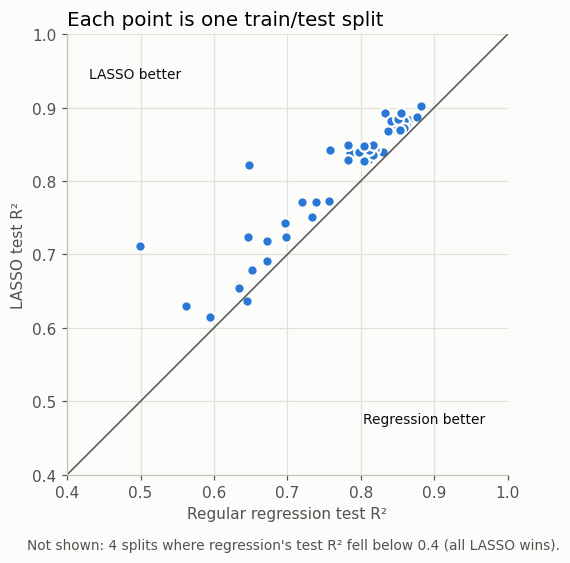

In [11]:
off_chart = (runs["r2_ols"] < 0.4).sum()

fig, ax = plt.subplots(figsize=(6.2, 5.2))
ax.plot([0.4, 1], [0.4, 1], color=INK, lw=1)
ax.scatter(runs["r2_ols"], runs["r2_lasso"], s=48, color=BLUE, edgecolors="#fcfcfb", linewidths=1.5)
ax.annotate("LASSO better", (0.43, 0.94), fontsize=9, color="#0b0b0b")
ax.annotate("Regression better", (0.97, 0.47), fontsize=9, color="#0b0b0b", ha="right")
ax.set(xlim=(0.4, 1), ylim=(0.4, 1), aspect="equal", xlabel="Regular regression test R²",
       ylabel="LASSO test R²", title="Each point is one train/test split")
fig.text(0.13, -0.02, f"Not shown: {off_chart} splits where regression's test R² fell below 0.4 (all LASSO wins).",
         fontsize=9, color=INK)
plt.show()

## When does the result change?

A fair demonstration should also show where the gain shrinks. We run the same contest three more ways. This cell takes about 45 seconds to run.

- **Numeric inputs only:** no text columns at all.
- **Modeling log price:** the usual fix for skewed prices. Predictions are converted back to dollars before scoring.
- **No grouping of rare categories:** the coding choice we made earlier.

In [12]:
def row(runs):
    return {"Columns": round(runs["columns"].mean()),
            "Median R2, regression": round(runs["r2_ols"].median(), 3),
            "Median R2, LASSO": round(runs["r2_lasso"].median(), 3),
            "LASSO wins": f"{(runs['r2_lasso'] > runs['r2_ols']).mean():.0%}"}

pd.DataFrame({
    "All inputs, price": row(runs),
    "Numeric inputs only, price": row(compare(X.select_dtypes("number"), y)),
    "All inputs, log price": row(compare(X, y, log_price=True)),
    "All inputs, price, no grouping": row(compare(X, y, min_frequency=None)),
}).T

,Columns,"Median R2, regression","Median R2, LASSO",LASSO wins
"All inputs, price",206,0.791,0.836,98%
"Numeric inputs only, price",36,0.786,0.786,64%
"All inputs, log price",206,0.778,0.825,70%
"All inputs, price, no grouping",252,0.664,0.833,82%


- **Numeric only:** the two nearly tie, so the gain comes from the large number of columns created by the text inputs.
- **Log price:** LASSO still leads, but it wins less often.
- **No grouping:** the gap in median $R^2$ looks larger, but that gap is misleading.

## Why we grouped rare categories

Without grouping, on our original split, a $180,000 house was predicted at **−$509,015** by regression.

- It has a metal roof, which never appears in the training houses, so the coding treats it as the baseline roof type.
- That baseline is a single training house, so regression gave the other roof types coefficients of over $600,000.
- Remove this one house from the test set and regression actually beats LASSO on that split.

**The lesson:** check large wins before you trust them. Part of this gap came from how the data was coded, not from the model. After grouping, regression improves a lot, and LASSO still wins.

## Takeaways

- **LASSO can beat regression on the same inputs.** No squares or interactions were needed here.
- **Why it won:** with many columns, regression's coefficients get large and unstable, and it overfits. LASSO shrinks them and removes about half the columns.
- **How much it won by:** a steady but moderate gain, not a dramatic one. Both models still miss the most expensive houses.
- **It depends on the setup.** With numeric inputs only, the gain disappears, so always compare against plain regression.
- **Test it carefully.** Use several splits, and find out why a result looks surprisingly good.